# Highlights Analysis


## Import Libraries and Data

In [1]:
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

highlights_index = pd.read_csv("highlights_index.csv")

## Import Median Error Margins

In [2]:
ga_dem_median_error_margin = float(highlights_index.iloc[3, 1])
ga_rep_median_error_margin = float(highlights_index.iloc[4, 1])
ga_3rd_median_error_margin = float(highlights_index.iloc[5, 1])

me_dem_median_error_margin = float(highlights_index.iloc[9, 1])
me_rep_median_error_margin = float(highlights_index.iloc[10, 1])
me_3rd_median_error_margin = float(highlights_index.iloc[11, 1])

mi_dem_median_error_margin = float(highlights_index.iloc[15, 1])
mi_rep_median_error_margin = float(highlights_index.iloc[16, 1])
mi_3rd_median_error_margin = float(highlights_index.iloc[17, 1])

print((ga_dem_median_error_margin, ga_rep_median_error_margin, ga_3rd_median_error_margin))
print((me_dem_median_error_margin, me_rep_median_error_margin, me_3rd_median_error_margin))
print((mi_dem_median_error_margin, mi_rep_median_error_margin, mi_3rd_median_error_margin))

(0.1242, 0.0037, -3.0325)
(-0.1661, 0.0659, -0.2101)
(0.3, 3.8449, -4.87)


## Import 30 day analysis data

In [3]:
ga_dem_30_day_percentage = float(highlights_index.iloc[0, 1])
ga_rep_30_day_percentage = float(highlights_index.iloc[1, 1])
ga_3rd_30_day_percentage = float(highlights_index.iloc[2, 1])

me_dem_30_day_percentage = float(highlights_index.iloc[6, 1])
me_rep_30_day_percentage = float(highlights_index.iloc[7, 1])
me_3rd_30_day_percentage = float(highlights_index.iloc[8, 1])

mi_dem_30_day_percentage = float(highlights_index.iloc[12, 1])
mi_rep_30_day_percentage = float(highlights_index.iloc[13, 1])
mi_3rd_30_day_percentage = float(highlights_index.iloc[14, 1])

print((ga_dem_30_day_percentage, ga_rep_30_day_percentage, ga_3rd_30_day_percentage))
print((me_dem_30_day_percentage, me_rep_30_day_percentage, me_3rd_30_day_percentage))
print((mi_dem_30_day_percentage, mi_rep_30_day_percentage, mi_3rd_30_day_percentage))

(34.8, 52.3, 12.9)
(37.5, 37.3, 25.2)
(56.2, 34.5, 9.3)


## Create Bar Chart for 30 day

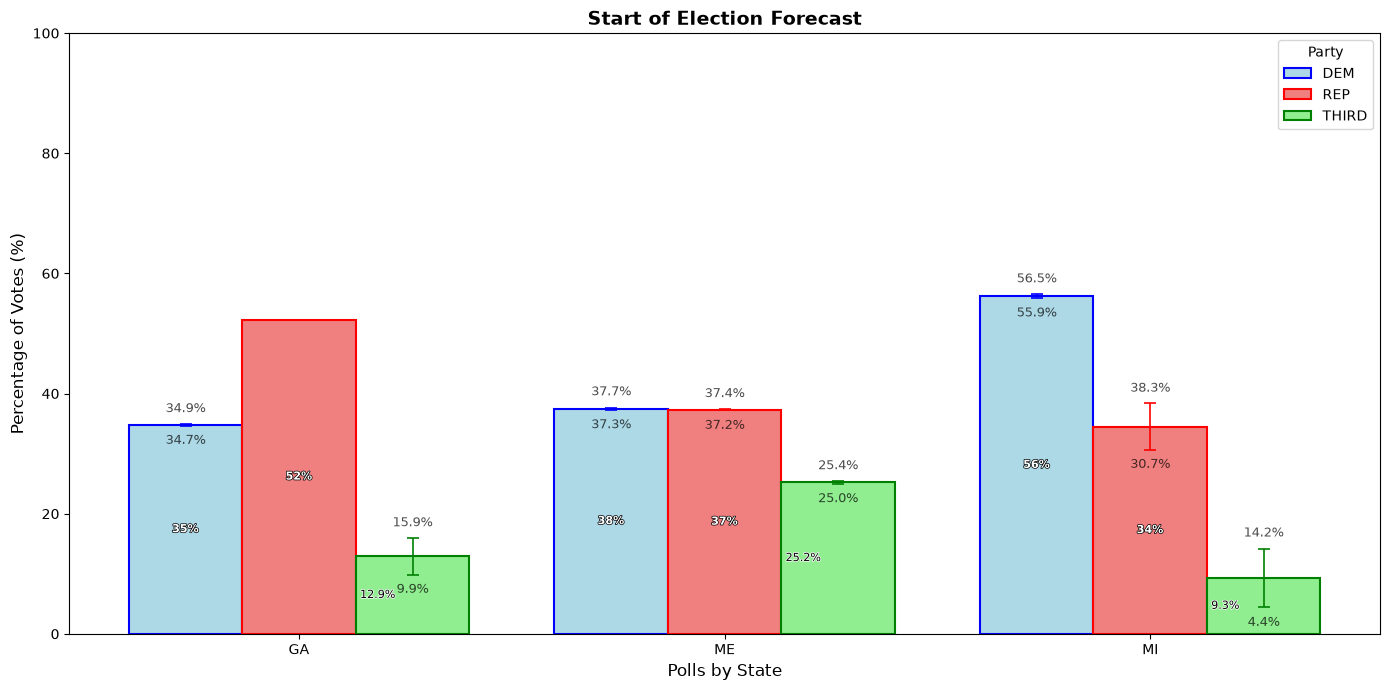

In [4]:
data_bar_chart = [
    {"ga_dem": ga_dem_30_day_percentage, "ga_rep": ga_rep_30_day_percentage, "ga_3rd": ga_3rd_30_day_percentage},
    {"me_dem": me_dem_30_day_percentage, "me_rep": me_rep_30_day_percentage, "me_3rd": me_3rd_30_day_percentage},
    {"mi_dem": mi_dem_30_day_percentage, "mi_rep": mi_rep_30_day_percentage, "mi_3rd": mi_3rd_30_day_percentage}
]

data_error_margins = [
    {"ga_dem": ga_dem_median_error_margin, "ga_rep": ga_rep_median_error_margin, "ga_3rd": ga_3rd_median_error_margin},
    {"me_dem": me_dem_median_error_margin, "me_rep": me_rep_median_error_margin, "me_3rd": me_3rd_median_error_margin},
    {"mi_dem": mi_dem_median_error_margin, "mi_rep": mi_rep_median_error_margin, "mi_3rd": mi_3rd_median_error_margin}
]

states = ["GA", "ME", "MI"]
parties = ["DEM", "REP", "THIRD"]

# ---- 1. Flatten your data into a (state, party) -> value lookup ----
key_suffix = {"DEM": "dem", "REP": "rep", "THIRD": "3rd"}

bar_chart_polling_values = {}
for state_idx, state in enumerate(states):
    entry = data_bar_chart[state_idx]          
    for party in parties:
        key = f"{state.lower()}_{key_suffix[party]}"
        bar_chart_polling_values[(state, party)] = entry[key]
        
error_margins = {}
for state_idx, state in enumerate(states):
    entry = data_error_margins[state_idx]
    for party in parties:
        key = f"{state.lower()}_{key_suffix[party]}"
        error_margins[(state, party)] = abs(entry[key])

# ---- 2. Layout ----
n_states = len(states)
n_parties = len(parties)

total_width = 0.8
bar_width = total_width / n_parties   # 3 bars per cluster

x = np.arange(n_states)

def bar_offset(k, n):
    """Center k-th of n bars around x=0."""
    return (k - (n - 1) / 2) * bar_width

party_styles = {
    "DEM":   {"face": "lightblue",  "edge": "blue"},
    "REP":   {"face": "lightcoral", "edge": "red"},
    "THIRD": {"face": "lightgreen", "edge": "green"},
}

# ---- 3. Plot ----
fig, ax = plt.subplots(figsize=(14, 7))

for state_idx, state in enumerate(states):
    for party_idx, party in enumerate(parties):
        value = bar_chart_polling_values[(state, party)]
        err   = error_margins[(state, party)]
        style = party_styles[party]
        offset = bar_offset(party_idx, n_parties)
        xpos = x[state_idx] + offset

        # Bar with built-in error bar
        ax.bar(
            xpos, value,
            width=bar_width,
            color=style["face"],
            edgecolor=style["edge"],
            linewidth=1.5,
            yerr=err,
            capsize=4,
            error_kw={"ecolor": style["edge"], "elinewidth": 1.2, "capthick": 1.2},
            label=party if state_idx == 0 else None,
        )

        # Center value label inside the bar (your existing one)
        if party == "THIRD" or value < 15:
            ax.text(
                xpos - bar_width / 2 + 0.01,   # left edge of the bar (+ tiny padding)
                value / 2,
                f"{value:.1f}%",
                ha="left", va="center",
                fontsize=8, color="black",
                path_effects=[pe.withStroke(linewidth=1, foreground="white")]
            )
        else:
            ax.text(
                xpos, value / 2,
                f"{value:.0f}%",
                ha="center", va="center",
                fontsize=8, color="white", fontweight="bold",
                path_effects=[pe.withStroke(linewidth=1, foreground="black")],
            )

        # Upper / lower bound labels
        upper = round(value + err, 1)
        lower = round(value - err, 1)
        if upper != lower:
            ax.text(xpos, upper + 1.5, f"{upper:.1f}%",
                    ha="center", va="bottom", fontsize=9,
                    color="black", alpha=0.7)
            ax.text(xpos, lower - 1.5, f"{lower:.1f}%",
                    ha="center", va="top", fontsize=9,
                    color="black", alpha=0.7)

# ---- 4. Axes ----
ax.set_xticks(x)
ax.set_xticklabels(states, fontsize=10)
ax.set_xlabel("Polls by State", fontsize=12)
ax.set_ylabel("Percentage of Votes (%)", fontsize=12)
ax.set_title("Start of Election Forecast", fontsize=14, fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(title="Party", loc="upper right")

plt.tight_layout()
plt.savefig(
    f"_static/images/start_election_forecast.png", dpi=300, bbox_inches="tight"
)
plt.show()